# 03. 조건부 Edge - 가위바위보 승부 판정(문제)
`03_conditional_edge.ipynb`의 점검 문제를 직접 풀어본다. 지금까지는 `score` 하나의 값만 보고 분기했지만, 이번에는 `player`와 `computer` **두 값을 비교**해서 분기하는 조건부 Edge를 만든다. 가위바위보 승부를 판정하는 Graph이다.

아래 TODO 주석을 채워서 코드를 완성한 뒤, 맨 아래 자가 점검용 테스트를 통과시킨다. 정답은 보지 않고 먼저 풀어본다.

## 요구사항
- State에는 `player`, `computer`, `result` 세 필드가 있다(`player`, `computer`는 `"가위"`, `"바위"`, `"보"` 중 하나).
- Routing 함수는 `player`와 `computer`를 비교해 `"win"`, `"lose"`, `"draw"` 중 하나를 반환한다.
- 가위는 보를 이기고, 바위는 가위를 이기고, 보는 바위를 이긴다.
- 각 결과에 맞는 Node를 만들어 `result`에 `"승리"`, `"패배"`, `"무승부"`를 채운다.

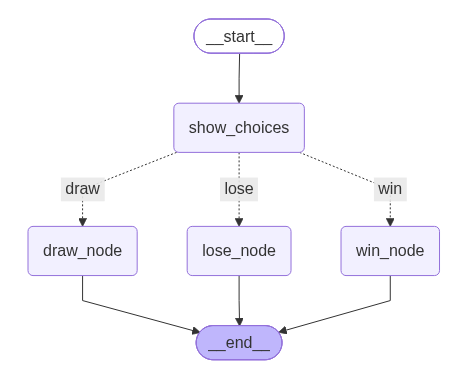

## 힌트
- `player`와 `computer`가 같은 경우를 가장 먼저 확인하면 무승부 처리가 단순해진다.
- 경우의 수는 3×3 = 9가지이지만, "player가 computer를 이기는 조합" 3가지만 집합(`set`)으로 정의하면 나머지는 자동으로 패배로 처리할 수 있다.

In [10]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# TODO: player, computer, result 세 필드를 가진 State 스키마를 정의한다. TypedDict 상속받기
class RPSState():
    # 여기에 player, computer, result 필드를 정의하세요. 모두 문자열임
    player: str
    computer: str
    result: str

def show_choices(state: RPSState) -> dict:
    print(f"실행 Node: show_choices (player={state['player']}, computer={state['computer']})")
    return {"player" : state['player'], "computer" : state['computer']}  # 값을 바꾸지 않고 그대로 다음 분기로 넘긴다.


# "player가 computer를 이기는 조합"만 집합으로 정의해 비교를 단순화한다.
WINNING_COMBOS = {("가위", "보"), ("바위", "가위"), ("보", "바위")}

# 결과를 판단하는 조건 분기 함수 정의
def judge(state: RPSState) -> str:
    pair = (state["player"], state["computer"])
    if state["player"] == state["computer"]:
        return "draw"  
    return "win" if pair in WINNING_COMBOS else "lose"


# TODO: 승리/패배/무승부 결과를 result에 채우는 Node를 각각 완성한다.
def win_node(state: RPSState) -> dict:
    # TODO: result에 '승리'를 담아 반환하도록 완성한다.
    return {"result": "승리"}

def lose_node(state: RPSState) -> dict:
    # TODO: result에 '패배'를 담아 반환하도록 완성한다.
    return {"result": "패배"}

def draw_node(state: RPSState) -> dict:
    # TODO: result에 '무승부'를 담아 반환하도록 완성한다.
    return {"result": "무승부"}

# TODO: builder 객체 생성
builder = StateGraph(RPSState)

# TODO: builder에 show_choices, judge, win_node, lose_node, draw_node를 Node로 추가한다.
builder.add_node("show_choices", show_choices)
builder.add_node("win_node", win_node)
builder.add_node("lose_node", lose_node)
builder.add_node("draw_node", draw_node)


# TODO: START에서 show_choices로 Edge를 연결한다.
builder.add_edge(START, "show_choices")
# TODO: show_choices Node에서 judge 함수로 조건분기 Edge 연결하기
# judge에서 RPSState의 상태에 따라 win_node, lose_node, draw_node로 조건 분기 Edge를 연결한다.
builder.add_conditional_edges(
    "show_choices",
    judge,
    {
        "win": "win_node",
        "lose": "lose_node",
        "draw": "draw_node"
    }
)
builder.add_edge("win_node", END)
builder.add_edge("lose_node", END)
builder.add_edge("draw_node", END)

graph3 = builder.compile()

## 그래프 시각화
위 코드를 완성하고 나면 아래 셀로 Graph 구조를 확인한다.

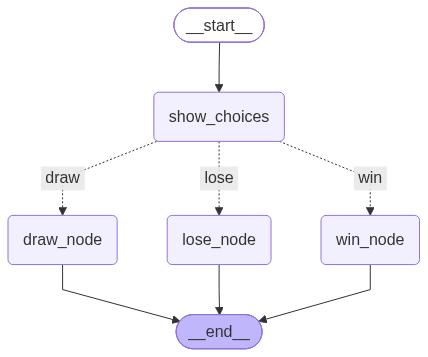

In [11]:
graph3

In [ ]:
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph3.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph3.get_graph().draw_mermaid())

## 자가 점검용 테스트
아래 테스트를 모두 통과하면 완성이다. 통과하지 못하면 `judge()`의 분기 조건을 다시 확인한다.

In [12]:
cases = [
    ("가위", "보", "승리"),
    ("가위", "바위", "패배"),
    ("가위", "가위", "무승부"),
    ("바위", "가위", "승리"),
    ("보", "바위", "승리"),
    ("보", "가위", "패배"),
]
for player, computer, expected in cases:
    print(f"\n입력: player={player}, computer={computer}")
    result = graph3.invoke({"player": player, "computer": computer, "result": "미정"})
    print("최종 State:", result)
    assert result["result"] == expected
print("\n모든 케이스 통과")


입력: player=가위, computer=보
실행 Node: show_choices (player=가위, computer=보)
최종 State: {'player': '가위', 'computer': '보', 'result': '승리'}

입력: player=가위, computer=바위
실행 Node: show_choices (player=가위, computer=바위)
최종 State: {'player': '가위', 'computer': '바위', 'result': '패배'}

입력: player=가위, computer=가위
실행 Node: show_choices (player=가위, computer=가위)
최종 State: {'player': '가위', 'computer': '가위', 'result': '무승부'}

입력: player=바위, computer=가위
실행 Node: show_choices (player=바위, computer=가위)
최종 State: {'player': '바위', 'computer': '가위', 'result': '승리'}

입력: player=보, computer=바위
실행 Node: show_choices (player=보, computer=바위)
최종 State: {'player': '보', 'computer': '바위', 'result': '승리'}

입력: player=보, computer=가위
실행 Node: show_choices (player=보, computer=가위)
최종 State: {'player': '보', 'computer': '가위', 'result': '패배'}

모든 케이스 통과


## 보너스: 랜덤 컴퓨터와 대결
테스트를 모두 통과했다면, 컴퓨터가 매번 무작위로 내는 버전도 실행해본다. 실행할 때마다 결과가 달라질 수 있다.

In [13]:
import random

player_choice = "바위"  # 원하는 값으로 바꿔본다.
computer_choice = random.choice(["가위", "바위", "보"])
bonus_result = graph3.invoke({"player": player_choice, "computer": computer_choice, "result": "미정"})
print("최종 State:", bonus_result)

실행 Node: show_choices (player=바위, computer=보)
최종 State: {'player': '바위', 'computer': '보', 'result': '패배'}
